In [ ]:
%matplotlib inline

# Solution 6 (optional) — Misalignments and vertical emittance

Apply random quadrupole shifts to the DBA ring and compare the vertical orbit, dispersion, and equilibrium emittance with the ideal ring. Complete the missing code.

### Load the ring

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xtrack as xt

ring = xt.load('ring_dba.json')

Done loading line from dict.           


### Ideal-ring emittances

As in notebook 3, use a sliced copy to sample the optics inside the magnets.

In [2]:
slicing_strategies = [
    xt.Strategy(slicing=None),
    xt.Strategy(slicing=xt.Uniform(100, mode='thick'), element_type=xt.Bend),
    xt.Strategy(slicing=xt.Uniform(2, mode='thick'), element_type=xt.Quadrupole),
]

ring_rad = ring.copy()
ring_rad.slice_thick_elements(slicing_strategies=slicing_strategies)
tw_ideal = ring_rad.twiss4d(radiation_integrals=True)
print('Horizontal emittance:', tw_ideal.rad_int_eq_gemitt_x)  # m rad
print('Vertical emittance:', tw_ideal.rad_int_eq_gemitt_y)  # m rad

Horizontal emittance: 8.26417538889058e-09
Vertical emittance: 0.0


### Misalign the quadrupoles

Use an independent copy of the ring. Apply independent Gaussian horizontal and vertical shifts with 10 µm RMS to all quadrupoles. Keep the random seed fixed to reproduce the same errors.

In [3]:
ring_errors = ring.copy()
tt = ring_errors.get_table()
quad_names = tt.rows[tt.element_type == 'Quadrupole'].name

rng = np.random.default_rng(2026)
sigma_shift = 10e-6  # m
shift_x = rng.normal(scale=sigma_shift, size=len(quad_names))
shift_y = rng.normal(scale=sigma_shift, size=len(quad_names))

for name, dx, dy in zip(quad_names, shift_x, shift_y):
    ring_errors[name].shift_x = dx
    ring_errors[name].shift_y = dy

### Recompute the optics and radiation integrals

Use the same slicing as for the ideal ring. Leave the orbit uncorrected.

In [4]:
ring_errors.slice_thick_elements(slicing_strategies=slicing_strategies)
tw_errors = ring_errors.twiss4d(radiation_integrals=True)

### Vertical closed orbit

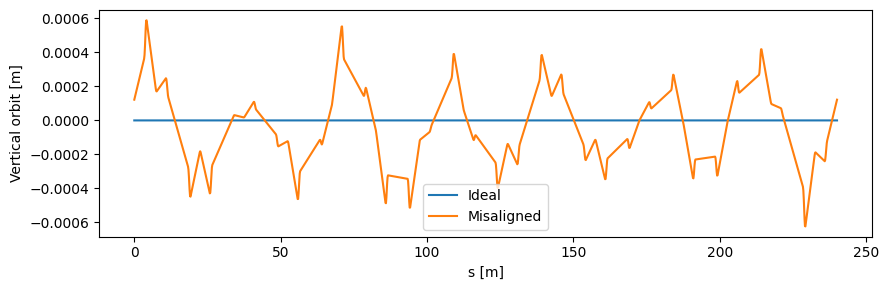

In [5]:
plt.figure(figsize=(9, 3))
plt.plot(tw_ideal.s, tw_ideal.y, label='Ideal')
plt.plot(tw_errors.s, tw_errors.y, label='Misaligned')
plt.xlabel('s [m]')
plt.ylabel('Vertical orbit [m]')
plt.legend()
plt.tight_layout()

### Vertical dispersion

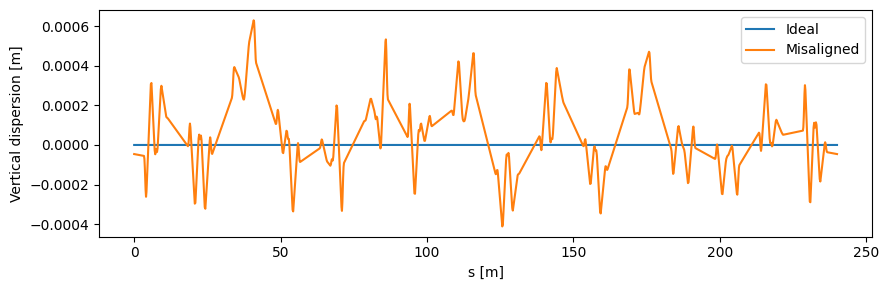

In [6]:
plt.figure(figsize=(9, 3))
plt.plot(tw_ideal.s, tw_ideal.dy, label='Ideal')
plt.plot(tw_errors.s, tw_errors.dy, label='Misaligned')
plt.xlabel('s [m]')
plt.ylabel('Vertical dispersion [m]')
plt.legend()
plt.tight_layout()

### Horizontal equilibrium emittance

In [7]:
print('Ideal:', tw_ideal.rad_int_eq_gemitt_x)  # m rad
print('Misaligned:', tw_errors.rad_int_eq_gemitt_x)  # m rad

Ideal: 8.26417538889058e-09
Misaligned: 8.259539020252326e-09


### Vertical equilibrium emittance

In [8]:
print('Ideal:', tw_ideal.rad_int_eq_gemitt_y)  # m rad
print('Misaligned:', tw_errors.rad_int_eq_gemitt_y)  # m rad

Ideal: 0.0
Misaligned: 5.173605162157726e-13


Why is the vertical emittance now nonzero? Try doubling the RMS shift with the same seed and rerunning. How does the vertical emittance change?

These radiation integrals estimate the emittance from vertical dispersion; they do not describe the full coupled equilibrium.